# 5. lecke – King County lakásárbecslés

**Feltevés.** Az eladás napján ismert jellemzők használhatók, a comps csak korábbi tanítóeladásokból származhat, és az ingatlanazonosító a megadott mezőkből képzett közelítés. A validáció és a teszt jövőbeli időblokkok; ugyanaz a közelítő ingatlan nem szerepelhet a tanító- és az értékelt részben.

## 1. Kérdés és előre rögzített mérőszámok

Az előrejelzett mennyiség az eladási ár USD-ben; fedezetértékelésnél a túlbecslés lehet költségesebb, ezért elsődleges mérőszámként a dollárban kifejezett RMSE-t és modellválasztási szabályként is a fejlesztési foldok RMSE-átlagát rögzítem. Másodlagosan közlöm a WAPE-t, MAE-t, RMSLE-t, R²-t és a jósolt/tényleges összeg arányát; utóbbi a log-cél visszaalakítási torzítását is jelzi. A tesztet a végén egyszer értékelem, és nem hangolok rajta.


In [1]:
from pathlib import Path
import sys

module_dir = Path("lesson 5")
if not module_dir.is_dir():
    module_dir = Path(".")
sys.path.insert(0, str(module_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import house as H
from results import compute

plt.rcParams["figure.dpi"] = 80
R, O = compute()


## 1b. Feltárás, tisztítás és időrendi felosztás

A célár ferde eloszlását nyers és log1p skálán, a földrajzi árkülönbséget, a havi mediánt és a lakóterület kapcsolatát a fejlesztési adaton ábrázolom. A ≥10 hálószobás öt sort – köztük a 33 hálószobásat – elhagyom, mert valószínű adathibák; az árakat nem csonkolom, a `yr_renovated=0` értéket „nem volt felújításként” jelzem, a ZIP-kód pedig kategória.

A teszt az időrend utolsó 20%-a, 2015-03-10-től: a véletlen vágás szomszédos eladásokat keverne a tanítóba. A 13 hónap miatt a teszt egyetlen szezon, a fák nem extrapolálnak; a három kiterjedő időablakos foldban minden validációs ingatlan korábbi tanítóeladását kizárom.


sorok: 21,608/21,613 | fejlesztés: 17,277 | záró teszt (egyszer, a végén): 4,331 | vágás: 2015-03-10 | modell: XGBoost
Az eredeti maximum 33 hálószoba; a felújítási év 0 az esetek 95.8%-ában szerepel.
Árátlag $540,088, medián $450,000, maximum $7,700,000; hiányzó érték 0.
5 sort hagytam el a legalább 10 hálószobás szélsőség miatt; 392 sor osztozik 195 ismétlődő kulcson. A fejlesztési utolsó dátum 2015-03-09, és 99 korábbi eladást zártam ki a teszt miatt.


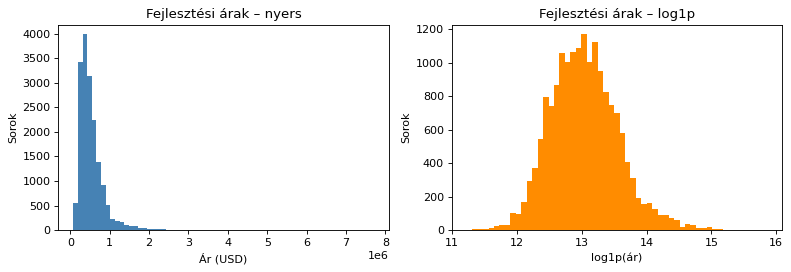

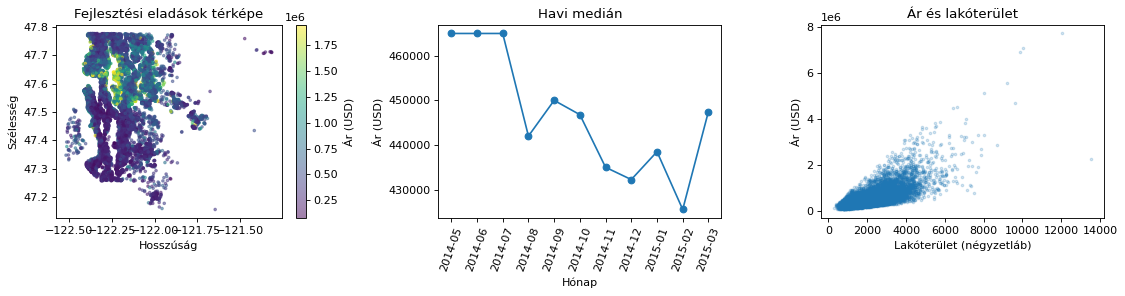

A log1p skála tömöríti a hosszú jobb farkat; az 1M USD feletti arány 6.8%, és 70 ZIP-kód szerepel.


In [2]:
d = O["frame"]
dev = d.loc[d["date"] < H.DEV_END]
print(
    f"sorok: {R['data']['rows']:,}/{R['data']['source_rows']:,} | "
    f"fejlesztés: {R['data']['dev_rows']:,} | "
    f"záró teszt (egyszer, a végén): {R['data']['test_rows']:,} | "
    f"vágás: {R['data']['dev_end']} | modell: {R['data']['engine']}"
)
print(
    f"Az eredeti maximum {R['data']['original_max_bedrooms']} hálószoba; a felújítási év 0 "
    f"az esetek {R['data']['renovation_zero_rate']:.1%}-ában szerepel."
)
print(
    f"Árátlag ${R['data']['mean_price']:,.0f}, medián ${R['data']['median_price']:,.0f}, "
    f"maximum ${R['data']['max_price']:,.0f}; hiányzó érték {R['data']['missing_values']}."
)
print(
    f"{R['data']['removed_bedroom_rows']} sort hagytam el a legalább 10 hálószobás szélsőség miatt; "
    f"{R['data']['repeat_rows']} sor osztozik {R['data']['repeat_properties']} ismétlődő kulcson. "
    f"A fejlesztési utolsó dátum {dev.date.max():%Y-%m-%d}, és {R['data']['test_purged_rows']} korábbi eladást zártam ki a teszt miatt."
)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(dev["price"], bins=65, color="steelblue")
ax[0].set(title="Fejlesztési árak – nyers", xlabel="Ár (USD)", ylabel="Sorok")
ax[1].hist(np.log1p(dev["price"]), bins=55, color="darkorange")
ax[1].set(title="Fejlesztési árak – log1p", xlabel="log1p(ár)", ylabel="Sorok")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
s = ax[0].scatter(dev["long"], dev["lat"], c=dev["price"], s=5, alpha=.5, cmap="viridis",
                  vmax=dev["price"].quantile(.99))
ax[0].set(title="Fejlesztési eladások térképe", xlabel="Hosszúság", ylabel="Szélesség")
fig.colorbar(s, ax=ax[0], label="Ár (USD)")
monthly = dev.assign(month=dev["date"].dt.to_period("M")).groupby("month")["price"].median()
ax[1].plot(monthly.index.astype(str), monthly.values, marker="o")
ax[1].tick_params(axis="x", rotation=70)
ax[1].set(title="Havi medián", xlabel="Hónap", ylabel="Ár (USD)")
ax[2].scatter(dev["sqft_living"], dev["price"], s=5, alpha=.2)
ax[2].set(title="Ár és lakóterület", xlabel="Lakóterület (négyzetláb)", ylabel="Ár (USD)")
plt.tight_layout()
plt.show()
print(
    f"A log1p skála tömöríti a hosszú jobb farkat; az 1M USD feletti arány "
    f"{R['data']['over_million_rate']:.1%}, és {R['data']['zip_count']} ZIP-kód szerepel."
)


## 2. Modell-létra – azonos időrendi foldok

A lineáris `lr_fair` ZIP one-hot kódolást, standardizált numerikus jellemzőket és log-területet használ. Az `lr_naive` a ZIP-et szándékosan egyetlen számként kezeli: negatív példa a kategóriák rendezett számként való bevezetésére; a faalapú modellek log1p áron tanulnak.


In [3]:
ladder = R["ladder"].copy()
ladder["fold_rmse"] = ladder["fold_rmse"].map(lambda values: [round(value) for value in values])
display(ladder[["modell", "rmse", "mae", "wape", "rmsle", "r2", "ratio", "fold_rmse"]].style.format({
    "rmse": "${:,.0f}", "mae": "${:,.0f}", "wape": "{:.3f}", "rmsle": "{:.3f}",
    "r2": "{:.3f}", "ratio": "{:.3f}",
}))
best = ladder.iloc[0]
print(
    f"A legkisebb OOF-RMSE a(z) {best['modell']} modellé (${best['rmse']:,.0f}); "
    f"WAPE={best['wape']:.3f}, R²={best['r2']:.3f}, összegarány={best['ratio']:.3f}."
)
print(
    f"A fold-RMSE-k {best['fold_rmse']}; az átlag baseline RMSE-je "
    f"${ladder.loc[ladder.modell == 'átlag', 'rmse'].iloc[0]:,.0f}."
)
if R["data"]["engine"] == "XGBoost":
    print("Motor: XGBoost.")
else:
    print(f"Az XGBoost helyett használt eljárás: {R['data']['engine']}.")


,modell,rmse,mae,wape,rmsle,r2,ratio,fold_rmse
0,lr_fair,"$128,240","$72,745",0.138,0.184,0.877,0.970,"[124812, 128423, 131464]"
1,xgb,"$132,921","$69,342",0.132,0.178,0.868,0.968,"[144019, 127727, 125361]"
2,forest,"$139,752","$71,402",0.136,0.182,0.854,0.964,"[136897, 141787, 140856]"
3,tree,"$174,057","$88,768",0.169,0.220,0.774,0.974,"[176033, 177452, 169047]"
4,lr_naive,"$186,576","$106,505",0.202,0.253,0.740,0.962,"[178455, 168425, 208115]"
5,ZIP-medián,"$294,077","$154,300",0.293,0.371,0.354,0.902,"[299629, 304143, 279292]"
6,átlag,"$366,217","$237,084",0.451,0.564,-0.002,1.030,"[376772, 366368, 355088]"


A legkisebb OOF-RMSE a(z) lr_fair modellé ($128,240); WAPE=0.138, R²=0.877, összegarány=0.970.
A fold-RMSE-k [124812, 128423, 131464]; az átlag baseline RMSE-je $366,217.
Motor: XGBoost.


## 3. Véletlen és időrendi validáció

Ugyanazt az XGBoostot kevert, 3 foldos KFold-dal is értékelem, de csak a kronológiai validációs blokkokkal közös sorokon hasonlítok. A véletlen és az időrendi RMSE különbségének előjele dönti el, hogy ebben a mérésben a véletlen felosztás kedvezőbb-e; ha igen, az sem bizonyít jövőbeli teljesítményt, ha nem, akkor sincs itt mérhető véletlen-felosztási előny. Az időrendi splitet azért választom, mert telepítéskor jövőbeli eladásokat jósolunk, és a piaci trend eltolhatja az árszintet; a házárak nem sűrű idősor, ezért a szomszédos eladások információszivárgása itt kicsi lehet.


In [4]:
split = R["split_comparison"]
split_table = pd.DataFrame([
    {"felosztás": name, **values}
    for name, values in split.items()
])
display(split_table[["felosztás", "rows", "rmse", "mae", "wape", "rmsle", "r2", "ratio"]].style.format({
    "rmse": "${:,.0f}", "mae": "${:,.0f}", "wape": "{:.3f}",
    "rmsle": "{:.3f}", "r2": "{:.3f}", "ratio": "{:.3f}",
}))
random_purged = split["property_purged"]["rmse"]
random_repeat = split["repeat_allowed"]["rmse"]
chron = split["chronological"]["rmse"]
print(
    f"Azonos {split['chronological']['rows']:,} validációs soron az időrendi RMSE ${chron:,.0f}, "
    f"a véletlen+purgált ${random_purged:,.0f}, az ismétlést bent hagyó ${random_repeat:,.0f}."
)
if random_purged < chron:
    print(
        f"A purgált véletlen split ${chron-random_purged:,.0f}-rel kisebb RMSE-t adott; "
        "ez ebben az összevetésben véletlen split-előny, de nem igazolja a jövőbeli teljesítményt."
    )
else:
    print(
        f"A purgált véletlen split ${random_purged-chron:,.0f}-rel nagyobb RMSE-t adott, "
        "tehát itt nem jobb az időrendi felosztásnál. Mivel a házárak nem sűrű idősorok, "
        "a szomszédos eladások közötti információszivárgás ebben a mérésben kicsi lehet; "
        "az időrendi felosztás ettől függetlenül a jövőbeli piaci szinteltolódást méri."
    )
repeat_purge_gap = abs(random_repeat - random_purged)
purge_comparison = "kisebb" if random_repeat < random_purged else "nagyobb"
if random_repeat < chron:
    print(
        f"Az ismétlést bent hagyó változat RMSE-je ${repeat_purge_gap:,.0f}-rel {purge_comparison} a purgáltnál, "
        f"és ${chron-random_repeat:,.0f}-rel kisebb az időrendi értéknél, ami az ismétlődő eladásokból eredő optimizmus lehet."
    )
else:
    print(
        f"Az ismétlést bent hagyó változat RMSE-je ${repeat_purge_gap:,.0f}-rel {purge_comparison} a purgáltnál, "
        f"és ${random_repeat-chron:,.0f}-rel nagyobb az időrendi értéknél, tehát itt ez a random változat sem jobb a jövőbeli blokk mérésénél."
    )
print("A kronológiai felosztás célja a jövőbeli értékesítések és az esetleges piaci szinteltolódás modellezése.")


,felosztás,rows,rmse,mae,wape,rmsle,r2,ratio
0,chronological,7462,"$132,921","$69,342",0.132,0.178,0.868,0.968
1,property_purged,7462,"$134,207","$69,088",0.131,0.178,0.865,0.974
2,repeat_allowed,7462,"$133,817","$69,358",0.132,0.178,0.866,0.974


Azonos 7,462 validációs soron az időrendi RMSE $132,921, a véletlen+purgált $134,207, az ismétlést bent hagyó $133,817.
A purgált véletlen split $1,286-rel nagyobb RMSE-t adott, tehát itt nem jobb az időrendi felosztásnál. Mivel a házárak nem sűrű idősorok, a szomszédos eladások közötti információszivárgás ebben a mérésben kicsi lehet; az időrendi felosztás ettől függetlenül a jövőbeli piaci szinteltolódást méri.
Az ismétlést bent hagyó változat RMSE-je $391-rel kisebb a purgáltnál, és $896-rel nagyobb az időrendi értéknél, tehát itt ez a random változat sem jobb a jövőbeli blokk mérésénél.
A kronológiai felosztás célja a jövőbeli értékesítések és az esetleges piaci szinteltolódás modellezése.


## 4. ZIP-kódolás és földrajzi jellemző

A `lr_naive` és `lr_fair` összevetése megmutatja, mennyit számít a ZIP kategóriaként kódolása. XGBoostnál azonos seedek mellett a `BASE − (BASE + GEO)` páros RMSE-különbséget mérem; pozitív érték a GEO változat javulása.


In [5]:
z = R["zipcode"]
print(
    f"lr_naive RMSE=${z['lr_naive_rmse']:,.0f} | lr_fair RMSE=${z['lr_fair_rmse']:,.0f} | "
    f"RMSE-különbség seedenként: {[round(x) for x in z['seed_differences']]} | "
    f"átlag ± sd: ${z['mean']:,.0f} ± ${z['sd']:,.0f}"
)
print(
    f"A ZIP egyetlen számként kezelése ${z['lr_naive_rmse']-z['lr_fair_rmse']:,.0f} RMSE-hátrányt ad. "
    f"A BASE−GEO különbség {z['mean']:+,.0f} USD, ami a földrajzi blokk hatását számszerűsíti."
)


lr_naive RMSE=$186,576 | lr_fair RMSE=$128,240 | RMSE-különbség seedenként: [4097, 7884, 6986, 5424, 5143] | átlag ± sd: $5,907 ± $1,514
A ZIP egyetlen számként kezelése $58,336 RMSE-hátrányt ad. A BASE−GEO különbség +5,907 USD, ami a földrajzi blokk hatását számszerűsíti.


## 5. Diagnosztika a legjobb modell out-of-fold jóslatain

A decilisek, a reziduumtölcsér, a térbeli log-reziduum-korreláció, az ár/kor/ZIP-szegmensek és a szélső vagy lehetetlen jóslatok mind a fejlesztési OOF-becslésekből készülnek. A ZIP- és comps-értékek foldon belül, kizárólag az adott tanító részből származnak; az ábrák ugyanennek az OOF-adatnak a mintázatait mutatják.


,decile,p_mean,y_mean,residual_sd,residual_mean,n
0,"(122937.48999999999, 243793.439]","$211,251","$217,439","$47,037","$6,187",747
1,"(243793.439, 288308.242]","$266,894","$270,824","$49,659","$3,930",746
2,"(288308.242, 334430.04]","$310,784","$313,750","$53,638","$2,966",746
3,"(334430.04, 385438.205]","$358,808","$365,372","$64,159","$6,563",746
4,"(385438.205, 433884.852]","$409,529","$416,344","$71,117","$6,815",746
5,"(433884.852, 492090.323]","$462,437","$474,105","$85,460","$11,668",746
6,"(492090.323, 557838.792]","$524,294","$532,197","$90,771","$7,903",746
7,"(557838.792, 653346.459]","$603,524","$617,520","$101,307","$13,995",746
8,"(653346.459, 845300.188]","$737,864","$756,469","$132,537","$18,605",746
9,"(845300.188, 6128011.549]","$1,219,866","$1,296,694","$312,525","$76,828",747


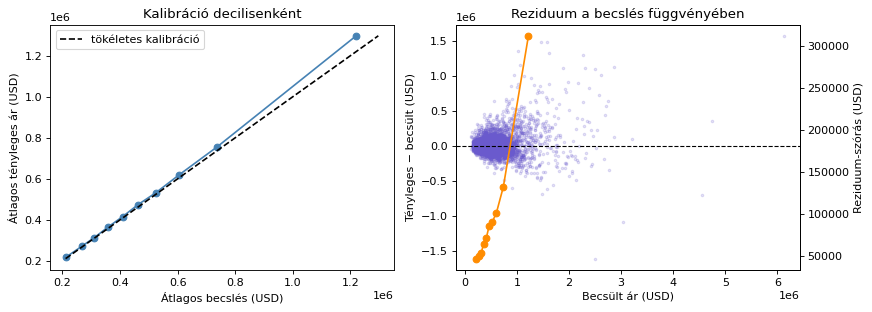

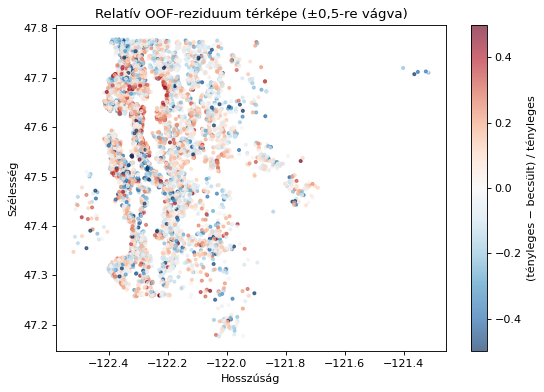

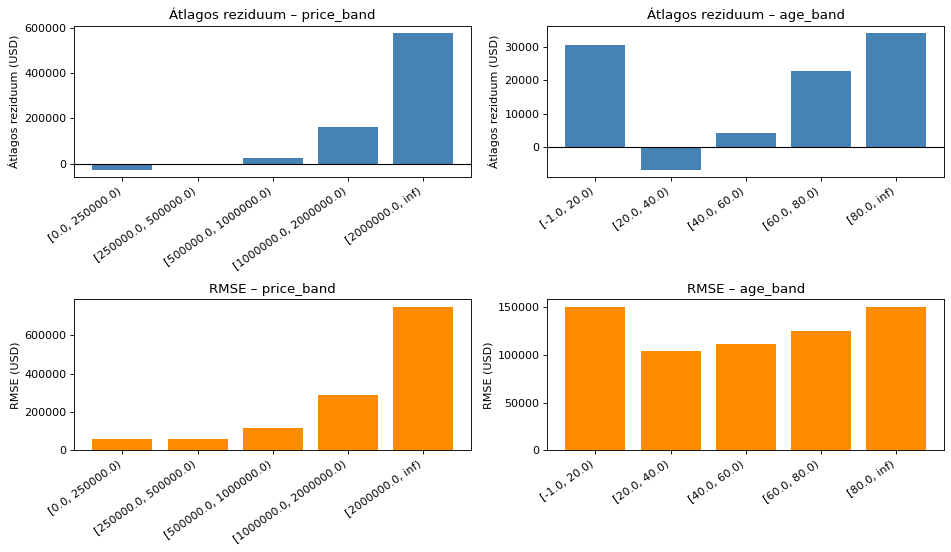

Tíz legnagyobb ZIP-kód:


,zipcode,n,mean_residual,rmse
0,98023,210,"$2,943","$52,566"
1,98034,199,"$25,833","$171,320"
2,98038,218,"$6,192","$62,131"
3,98042,183,"$5,258","$51,194"
4,98052,183,"$-5,085","$112,163"
5,98103,196,"$31,578","$139,255"
6,98115,186,"$24,766","$120,114"
7,98118,184,"$16,410","$107,807"
8,98133,188,"$-1,214","$82,629"
9,98155,172,"$-4,001","$68,564"


1. A decilisek átlagos becslése $211,251–$1,219,866, az átlagos tényleges ár $217,439–$1,296,694. A kalibrációban a legfelső decilis átlagos reziduuma $76,828; ezért ezt a sávot külön ellenőrizném.
2. A reziduum-szórás az első decilis $47,037, az utolsó $312,525 (arány 6.64). A növekvő tölcsér miatt a drága szegmens hibáját külön kezelném.
3. A legközelebbi, más ingatlanhoz tartozó OOF szomszédok log-reziduumával a korreláció 0.339. A térbeli együttmozgás miatt helyi földrajzi jellemzőt foldon belül tesztelnék.
4. A legnagyobb abszolút átlagos reziduum a vizsgált ár-, kor- és ZIP-szegmensekben $576,308. Ezt a csoportot célzottan mintáznám, de csak a fejlesztési foldokon.
5. A legolcsóbb decilis RMSE-je $59,469, a legdrágábbé $332,827. A foldonkénti árszint- és ár/négyzetláb-határokon kívüli jóslat 2; a legkisebb modelljóslat $122,937, ezért a szélső árakat mintavétellel vizsgálnám.


In [6]:
diag = O["diagnostics"]
display(diag["deciles"].style.format({
    "p_mean": "${:,.0f}", "y_mean": "${:,.0f}", "residual_sd": "${:,.0f}",
    "residual_mean": "${:,.0f}", "n": "{:,}",
}))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
cal = diag["deciles"]
ax[0].plot(cal["p_mean"], cal["y_mean"], marker="o", color="steelblue")
lo = min(cal["p_mean"].min(), cal["y_mean"].min())
hi = max(cal["p_mean"].max(), cal["y_mean"].max())
ax[0].plot([lo, hi], [lo, hi], linestyle="--", color="black", label="tökéletes kalibráció")
ax[0].set(title="Kalibráció decilisenként", xlabel="Átlagos becslés (USD)", ylabel="Átlagos tényleges ár (USD)")
ax[0].legend()
plot_data = diag["plot_data"]
ax[1].scatter(plot_data["p"], plot_data["residual"], s=5, alpha=.18, color="slateblue")
ax[1].axhline(0, color="black", linestyle="--", linewidth=1)
ax[1].set(title="Reziduum a becslés függvényében", xlabel="Becsült ár (USD)", ylabel="Tényleges − becsült (USD)")
ax_sd = ax[1].twinx()
ax_sd.plot(cal["p_mean"], cal["residual_sd"], marker="o", color="darkorange", label="decilis reziduum-szórása")
ax_sd.set_ylabel("Reziduum-szórás (USD)")
plt.tight_layout()
plt.show()

relative_residual = np.clip((plot_data["y"] - plot_data["p"]) / plot_data["y"], -.5, .5)
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(plot_data["long"], plot_data["lat"], c=relative_residual, s=7, alpha=.65, cmap="RdBu_r", vmin=-.5, vmax=.5)
ax.set(title="Relatív OOF-reziduum térképe (±0,5-re vágva)", xlabel="Hosszúság", ylabel="Szélesség")
fig.colorbar(sc, ax=ax, label="(tényleges − becsült) / tényleges")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(12, 7))
for axis, table, label in (
    (ax[0, 0], diag["by_price"], "price_band"),
    (ax[0, 1], diag["by_age"], "age_band"),
):
    positions = np.arange(len(table))
    axis.bar(positions, table["mean_residual"], color="steelblue")
    axis.axhline(0, color="black", linewidth=1)
    axis.set_xticks(positions, table[label].astype(str), rotation=35, ha="right")
    axis.set_ylabel("Átlagos reziduum (USD)")
    axis.set_title(f"Átlagos reziduum – {label}")
for axis, table, label in (
    (ax[1, 0], diag["by_price"], "price_band"),
    (ax[1, 1], diag["by_age"], "age_band"),
):
    positions = np.arange(len(table))
    axis.bar(positions, table["rmse"], color="darkorange")
    axis.set_xticks(positions, table[label].astype(str), rotation=35, ha="right")
    axis.set_ylabel("RMSE (USD)")
    axis.set_title(f"RMSE – {label}")
plt.tight_layout()
plt.show()

print("Tíz legnagyobb ZIP-kód:")
display(diag["by_zip"].style.format({"mean_residual": "${:,.0f}", "rmse": "${:,.0f}"}))
for number, sentence in enumerate(R["diagnostics"]["comments"], start=1):
    print(f"{number}. {sentence}")


## 6. Log-cél és visszaalakítás

A legjobb létramodell OOF-jóslatait log1p célon és nyers ár célon hasonlítom össze. Dollárban számolt RMSE mellett az RMSLE és a jósolt/tényleges összegarány mutatja, hogy az `expm1` visszaalakítás szisztematikusan alá- vagy fölébecsül-e.


In [7]:
target_table = pd.DataFrame(R["log_target"]).T
display(target_table[["rmse", "rmsle", "ratio"]].style.format({
    "rmse": "${:,.0f}", "rmsle": "{:.3f}", "ratio": "{:.3f}",
}))
log_ratio = R["log_target"]["log1p"]["ratio"]
print(
    f"log1p RMSE=${R['log_target']['log1p']['rmse']:,.0f}, összegarány={log_ratio:.3f}; "
    f"nyers cél RMSE=${R['log_target']['raw']['rmse']:,.0f}, arány={R['log_target']['raw']['ratio']:.3f}."
)
print(
    f"A log1p visszaalakított összeg aránya {log_ratio:.3f}, tehát a becsült összeg "
    f"{'lefelé' if log_ratio < 1 else 'felfelé'} torzít; ez indokolja az arány külön közlését."
)


,rmse,rmsle,ratio
log1p,"$128,240",0.184,0.970
raw,"$153,709",0.289,0.992


log1p RMSE=$128,240, összegarány=0.970; nyers cél RMSE=$153,709, arány=0.992.
A log1p visszaalakított összeg aránya 0.970, tehát a becsült összeg lefelé torzít; ez indokolja az arány külön közlését.


## 7. Visszacsatolás: először a hibás, majd a helyes comps

A következő feltevést kizárólag az 5. szakasz OOF-diagnosztikájából fogalmazom meg, és a fejlesztési foldokon ellenőrzöm. Az utólagos, szándékosan szivárgó példák szemléltetők, és semmilyen modell- vagy jellemzőválasztásban nem vesznek részt.


In [8]:
diag_summary = R["diagnostics"]
print(
    f"Feltevés: a térbeli reziduum-korreláció {diag_summary['spatial_corr']:.3f}, "
    f"a felső és alsó becslési decilis reziduum-szórásának aránya {diag_summary['funnel_ratio']:.2f}, "
    f"a legfelső decilis átlagos reziduuma ${diag_summary['top_decile_mean_residual']:,.0f}. "
    "Ez a GEO (lokális hely), RATIO (méret- és állapotarányok) és COMPS (közeli eladások) próbáját motiválja; "
    "a fák a sima földrajzi és arányhatásokat csak sok küszöbös felosztással, a foldonként változó comps-hatást pedig közvetlen összehasonlító nélkül ragadják meg."
)
leaky_table = R["leaky"][["modell", "rmse", "wape", "fold_rmse"]].copy()
leaky_table["fold_rmse"] = leaky_table["fold_rmse"].map(lambda values: [round(value) for value in values])
display(leaky_table.style.format({"rmse": "${:,.0f}", "wape": "{:.3f}"}))
correct_rmse = R["leaky"].loc[R["leaky"]["modell"] == "BASE + helyes fold-comps", "rmse"].iloc[0]
small_k_rmse = R["leaky"].loc[R["leaky"]["modell"] == "BASE + leaky k=3 comps", "rmse"].iloc[0]
zip_leak_rmse = R["leaky"].loc[R["leaky"]["modell"] == "BASE + leaky ZIP átlag", "rmse"].iloc[0]
print(
    f"A k=3 változat OOF-RMSE-je ${small_k_rmse:,.0f}, a teljes fejlesztési ZIP-átlagé ${zip_leak_rmse:,.0f}, "
    f"a helyes fold-compsé ${correct_rmse:,.0f}. A gyanúsan alacsony hiba a szivárgás tünete: "
    "mindkét leaky változat a validációs célértékeket is felhasználja, a k=3 változat pedig a saját sor ár/négyzetlábát is tartalmazza."
)
print("Ezek az utólagos, szivárgó változatok kizárólag demonstrációk, egyetlen döntéshez sem használom őket.")

ablation_rows = []
for item in R["feedback"]["ablation"]:
    row = {
        "változat": item["változat"],
        "javulás átlag (RMSE)": item["rmse_gain_mean"],
        "foldok közti sd": item["between_fold_sd"],
        "WAPE-javulás átlag": item["wape_gain_mean"],
        "RMSE-különbség CI": item["rmse_ci"],
        "bizonyított": item["proven"],
    }
    for fold in item["foldok"]:
        number = fold["fold"]
        row[f"F{number} RMSE ± sd"] = f"{fold['rmse_gain']:,.0f} ± {fold['rmse_sd']:,.0f}"
        row[f"F{number} WAPE ± sd"] = f"{fold['wape_gain']:.3f} ± {fold['wape_sd']:.3f}"
    ablation_rows.append(row)
display(pd.DataFrame(ablation_rows))
print(f"A szabály alapján bizonyított változatok: {R['feedback']['proven'] or 'nincs; a javulás nem bizonyítható'}.")
not_proven = [item['változat'] for item in R['feedback']['ablation'] if not item['proven']]
print(f"Nem bizonyítható változatok (nem teljesül a fold-feltétel): {not_proven or 'nincs'}.")
print("A különbség CI-je az ingatlanokat klaszterként mintázza (2 000 ismétlés); a pozitív RMSE-javulás a BASE hibájából levont új modellhibát jelenti.")
print("lr_fair + minden új jellemző foldonkénti RMSE-nyeresége: " + str([
    round(row["rmse_gain"]) for row in R["feedback"]["lr_fair_new"]
]) + " USD.")


Feltevés: a térbeli reziduum-korreláció 0.339, a felső és alsó becslési decilis reziduum-szórásának aránya 6.64, a legfelső decilis átlagos reziduuma $76,828. Ez a GEO (lokális hely), RATIO (méret- és állapotarányok) és COMPS (közeli eladások) próbáját motiválja; a fák a sima földrajzi és arányhatásokat csak sok küszöbös felosztással, a foldonként változó comps-hatást pedig közvetlen összehasonlító nélkül ragadják meg.


,modell,rmse,wape,fold_rmse
0,xgb BASE,"$132,921",0.132,"[144019, 127727, 125361]"
1,BASE + leaky k=3 comps,"$108,754",0.110,"[121837, 99629, 101979]"
2,BASE + leaky ZIP átlag,"$128,498",0.127,"[139792, 120527, 123053]"
3,BASE + helyes fold-comps,"$125,433",0.125,"[138417, 112300, 122208]"


A k=3 változat OOF-RMSE-je $108,754, a teljes fejlesztési ZIP-átlagé $128,498, a helyes fold-compsé $125,433. A gyanúsan alacsony hiba a szivárgás tünete: mindkét leaky változat a validációs célértékeket is felhasználja, a k=3 változat pedig a saját sor ár/négyzetlábát is tartalmazza.
Ezek az utólagos, szivárgó változatok kizárólag demonstrációk, egyetlen döntéshez sem használom őket.


,változat,javulás átlag (RMSE),foldok közti sd,WAPE-javulás átlag,RMSE-különbség CI,bizonyított,F1 RMSE ± sd,F1 WAPE ± sd,F2 RMSE ± sd,F2 WAPE ± sd,F3 RMSE ± sd,F3 WAPE ± sd
0,GEO,6293.752141,5123.226803,0.004190,"[2322.5411764891824, 10972.966073246029]",True,"9,836 ± 3,856",0.004 ± 0.002,"8,626 ± 1,897",0.007 ± 0.001,419 ± 962,0.002 ± 0.001
1,RATIO,594.497178,851.485348,0.000623,"[-216.40230595813082, 1466.181970178645]",False,"1,541 ± 1,593",0.002 ± 0.002,"351 ± 2,432",0.000 ± 0.001,"-109 ± 1,028",0.000 ± 0.001
2,COMPS,9113.507303,5487.686446,0.007347,"[4389.113763524197, 12236.43778137073]",True,"7,603 ± 1,960",0.006 ± 0.002,"15,198 ± 750",0.009 ± 0.001,"4,540 ± 1,261",0.007 ± 0.000
3,dist_seattle,3671.382402,2865.696513,0.001986,"[433.71941557624234, 7470.807794673223]",True,"5,757 ± 1,814",0.001 ± 0.001,"4,853 ± 2,733",0.004 ± 0.002,404 ± 768,0.001 ± 0.001
4,dist_bellevue,3446.673208,1922.020786,0.002265,"[1280.4146647241098, 5531.901194553067]",True,"3,841 ± 1,655",0.002 ± 0.001,"5,141 ± 1,517",0.003 ± 0.001,"1,358 ± 1,259",0.002 ± 0.002
5,rot1,2604.244731,966.605269,0.002731,"[1451.1566625500236, 3730.3782650814055]",True,"1,967 ± 1,490",0.003 ± 0.001,"3,716 ± 2,904",0.003 ± 0.001,"2,129 ± 642",0.003 ± 0.001
6,rot2,767.359718,1357.458644,-0.000013,"[-613.344043244344, 2003.3698191978624]",False,"576 ± 2,856",-0.001 ± 0.002,"2,210 ± 3,190",0.001 ± 0.001,-484 ± 744,-0.000 ± 0.001


A szabály alapján bizonyított változatok: ['GEO', 'COMPS', 'dist_seattle', 'dist_bellevue', 'rot1'].
Nem bizonyítható változatok (nem teljesül a fold-feltétel): ['RATIO', 'rot2'].
A különbség CI-je az ingatlanokat klaszterként mintázza (2 000 ismétlés); a pozitív RMSE-javulás a BASE hibájából levont új modellhibát jelenti.
lr_fair + minden új jellemző foldonkénti RMSE-nyeresége: [17898, 13522, 14002] USD.


## 8. Időbeli drift és extrapoláció

A fejlesztési időszak első felén tanítok, a második felén jósolok, az átfedő ingatlanokat itt is kizárom. Az RMSE és az összegarány számszerűsíti a driftet, de a következtetésnél külön összevetem a faalapú és lineáris változatokat.


In [9]:
drift_table = pd.DataFrame(R["drift"])
display(drift_table[["modell", "rmse", "ratio", "train_rows", "validation_rows"]].style.format({
    "rmse": "${:,.0f}", "ratio": "{:.3f}",
}))
for row in R["drift"]:
    print(f"{row['modell']}: RMSE=${row['rmse']:,.0f} | összegarány={row['ratio']:.3f}.")
tree_rows = [row for row in R["drift"] if row["modell"].startswith("xgb")]
linear_rows = [row for row in R["drift"] if row["modell"].startswith("lr_fair")]
tree_ratio = np.mean([row["ratio"] for row in tree_rows])
linear_ratio = np.mean([row["ratio"] for row in linear_rows])
tree_rmse = np.mean([row["rmse"] for row in tree_rows])
linear_rmse = np.mean([row["rmse"] for row in linear_rows])
ratio_gap = abs(tree_ratio - linear_ratio)
if ratio_gap <= .03:
    print(
        f"A boosting összegaránya átlagosan {tree_ratio:.3f}, a lineárisé {linear_ratio:.3f} "
        f"(különbség {ratio_gap:.3f}); az átlagos RMSE ${tree_rmse:,.0f} és ${linear_rmse:,.0f}. "
        "Ezek alapján nem látszik egyértelműen a fáknak tulajdonítható extrapolációs büntetés."
    )
elif tree_ratio < linear_ratio:
    print(
        f"A boosting összegaránya {tree_ratio:.3f}, a lineárisé {linear_ratio:.3f}, "
        f"az átlagos RMSE pedig ${tree_rmse:,.0f} és ${linear_rmse:,.0f}; a faalapú modellek erősebben lefelé torzítanak ezen a blokkon."
    )
else:
    print(
        f"A boosting összegaránya {tree_ratio:.3f}, a lineárisé {linear_ratio:.3f}, "
        f"az átlagos RMSE pedig ${tree_rmse:,.0f} és ${linear_rmse:,.0f}; ezen a blokkon a lineáris modellek összegaránya esik távolabb az 1-től."
    )


,modell,rmse,ratio,train_rows,validation_rows
0,xgb BASE,"$139,404",0.965,9740,7462
1,xgb BASE + legjobb jellemzők,"$129,512",0.975,9740,7462
2,lr_fair,"$129,017",0.972,9740,7462
3,lr_fair + új jellemzők,"$114,986",0.980,9740,7462


xgb BASE: RMSE=$139,404 | összegarány=0.965.
xgb BASE + legjobb jellemzők: RMSE=$129,512 | összegarány=0.975.
lr_fair: RMSE=$129,017 | összegarány=0.972.
lr_fair + új jellemzők: RMSE=$114,986 | összegarány=0.980.
A boosting összegaránya átlagosan 0.970, a lineárisé 0.976 (különbség 0.005); az átlagos RMSE $134,458 és $122,001. Ezek alapján nem látszik egyértelműen a fáknak tulajdonítható extrapolációs büntetés.


## 9. Cél újrafogalmazása

Azonos időrendi foldokon és a driftblokkban összevetem a log1p árszintet, a négyzetlábárat (ppsf) és a foldon belüli comps-árhoz viszonyított logarányt. A comps-alapú cél csak az adott tanító részből számított referenciaárra épül, visszaalakítás után mindhárom esetben USD-ben mérek.


In [10]:
reform = pd.DataFrame(R["reformulation"]["cv"])
display(reform[["cél", "rmse", "rmsle", "ratio"]].style.format({
    "rmse": "${:,.0f}", "rmsle": "{:.3f}", "ratio": "{:.3f}",
}))
for row in R["reformulation"]["drift"]:
    print(f"Drift – {row['cél']}: RMSE=${row['rmse']:,.0f} | RMSLE={row['rmsle']:.3f} | összegarány={row['ratio']:.3f}.")
best_target = min(R["reformulation"]["cv"], key=lambda row: row["rmse"])
print(
    f"CV-RMSE szerint a legjobb célalak {best_target['cél']} (${best_target['rmse']:,.0f}); "
    f"az eltérést a drift-összegarányokkal együtt értelmezem, nem teszt alapján választok."
)


,cél,rmse,rmsle,ratio
0,level,"$132,921",0.178,0.968
1,ppsf,"$118,701",0.180,0.994
2,logratio,"$116,281",0.173,0.978


Drift – level: RMSE=$139,404 | RMSLE=0.182 | összegarány=0.965.
Drift – ppsf: RMSE=$120,032 | RMSLE=0.181 | összegarány=0.994.
Drift – logratio: RMSE=$117,063 | RMSLE=0.175 | összegarány=0.977.
CV-RMSE szerint a legjobb célalak logratio ($116,281); az eltérést a drift-összegarányokkal együtt értelmezem, nem teszt alapján választok.


## 10. Végső választás, egyszeri teszt és klaszter-bootstrap

A modellválasztás előre rögzített szabálya a legkisebb fejlesztési fold-átlagos RMSE a jelöltek közül: XGBoost-alapmodell, a foldokon bizonyítottan javító XGBoost-változatok, `lr_fair`, illetve `lr_fair` az összes új jellemzővel. Az RMSE az elsődleges és a választási mutató dollárban, a WAPE, MAE, RMSLE, R² és az összegarány másodlagos; a teszt RMSE-jének alacsonyabb értéke nem ad okot utólagos hangolásra. A tesztet csak e szabály rögzítése után használom egyszer, majd ingatlanonkénti 2 000 ismétléses klaszter-bootstrapot alkalmazok.


In [11]:
print(R["final_rule"]["rule"])
print(R["final_rule"]["metric_reason"])
candidate_table = pd.DataFrame(R["final_rule"]["candidates"])
display(candidate_table.style.format({"mean_fold_rmse": "${:,.0f}"}))
final_metrics = pd.DataFrame(R["final"]["metrics"])
display(final_metrics[["modell", "rmse", "mae", "wape", "rmsle", "r2", "ratio"]].style.format({
    "rmse": "${:,.0f}", "mae": "${:,.0f}", "wape": "{:.3f}",
    "rmsle": "{:.3f}", "r2": "{:.3f}", "ratio": "{:.3f}",
}))
print(
    f"A nyertes {R['final_rule']['chosen']} CV-foldátlagos RMSE-je "
    f"${R['final_rule']['chosen_fold_rmse']:,.0f}; teszt-WAPE-je "
    f"{final_metrics.loc[final_metrics.modell == 'Kiválasztott', 'wape'].iloc[0]:.3f}."
)
bootstrap = R["final"]["bootstrap"]
print("95%-os klaszter-bootstrap intervallumok (2 000 mintázás, azonos ingatlan eladásai együtt):")
print(f"Nyertes RMSE: [${bootstrap['rmse'][0]:,.0f}, ${bootstrap['rmse'][1]:,.0f}].")
print(f"Nyertes WAPE: [{bootstrap['wape'][0]:.3f}, {bootstrap['wape'][1]:.3f}].")

def ci_status(bounds):
    if bounds[0] > 0:
        return "kizárja a nullát; az összehasonlító hibája nagyobb"
    if bounds[1] < 0:
        return "kizárja a nullát; a nyertes hibája nagyobb"
    return "tartalmazza a nullát"

for name, intervals in bootstrap["comparisons"].items():
    rmse_ci = intervals["rmse_difference"]
    wape_ci = intervals["wape_difference"]
    print(
        f"{name} − nyertes: ΔRMSE [${rmse_ci[0]:,.0f}, ${rmse_ci[1]:,.0f}] "
        f"({ci_status(rmse_ci)}), ΔWAPE [{wape_ci[0]:.3f}, {wape_ci[1]:.3f}] "
        f"({ci_status(wape_ci)})."
    )
print("A páros különbség = összehasonlító modell hibája − nyertes modell hibája.")
print("A tesztet nem használtam a modell- vagy célválasztásra, és utólagos hangolást nem végzek.")


A jelöltek közül a legkisebb fejlesztési fold-átlagos RMSE választ; tesztadat nem vesz részt a döntésben.
Az RMSE az elsődleges és modellválasztási mutató dollárban, mert a nagy hibákat erősen bünteti; a WAPE, MAE, RMSLE, R² és az összegarány másodlagos ellenőrző mutatók.


,name,mean_fold_rmse,fold_rmse
0,lr_fair + új jellemzők,"$113,093","[106914.14579085149, 114901.022569902, 117462.66801108739]"
1,xgb + COMPS,"$124,130","[138459.18583995118, 112770.09761317715, 121161.10102968979]"
2,xgb + GEO,"$126,798","[136108.47773406818, 119178.98578778292, 125106.60726267114]"
3,lr_fair,"$128,233","[124811.80908022317, 128423.41965971788, 131464.26663559332]"
4,xgb + dist_seattle,"$129,440","[140244.19659899, 122957.09481965027, 125119.53356789863]"
5,xgb + dist_bellevue,"$129,603","[142094.86982109473, 122519.17167594733, 124193.53589148598]"
6,xgb + rot1,"$130,553","[144008.99335750856, 124196.38494193983, 123453.05794469807]"
7,xgb BASE,"$133,140","[145926.0057505431, 127838.84051897466, 125655.35057393754]"


,modell,rmse,mae,wape,rmsle,r2,ratio
0,ZIP-medián,"$298,507","$157,876",0.285,0.366,0.341,0.856
1,lr_fair,"$138,928","$80,728",0.146,0.192,0.857,0.928
2,xgb BASE,"$137,975","$78,075",0.141,0.186,0.859,0.930
3,Kiválasztott,"$122,922","$73,338",0.132,0.178,0.888,0.934


A nyertes lr_fair + új jellemzők CV-foldátlagos RMSE-je $113,093; teszt-WAPE-je 0.132.
95%-os klaszter-bootstrap intervallumok (2 000 mintázás, azonos ingatlan eladásai együtt):
Nyertes RMSE: [$114,023, $132,053].
Nyertes WAPE: [0.128, 0.136].
ZIP-medián − nyertes: ΔRMSE [$151,783, $200,611] (kizárja a nullát; az összehasonlító hibája nagyobb), ΔWAPE [0.144, 0.161] (kizárja a nullát; az összehasonlító hibája nagyobb).
lr_fair − nyertes: ΔRMSE [$10,184, $22,120] (kizárja a nullát; az összehasonlító hibája nagyobb), ΔWAPE [0.011, 0.016] (kizárja a nullát; az összehasonlító hibája nagyobb).
xgb BASE − nyertes: ΔRMSE [$6,024, $25,579] (kizárja a nullát; az összehasonlító hibája nagyobb), ΔWAPE [0.005, 0.012] (kizárja a nullát; az összehasonlító hibája nagyobb).
A páros különbség = összehasonlító modell hibája − nyertes modell hibája.
A tesztet nem használtam a modell- vagy célválasztásra, és utólagos hangolást nem végzek.


## 11. Előrejelzési bizonytalansági sáv

Az 5. és 95. percentilis kvantilis modelleket csak a teszttől megtisztított fejlesztési adaton tanítom. A 90%-os névleges lefedettségtől való eltérést külön értelmezem: a fölötte mért lefedettség túl-lefedésre (konzervatív sávra), az alatta mért lefedettség alul-lefedésre utal.


In [12]:
u = R["uncertainty"]
print(
    f"Névleges lefedettség: 0.900 | mért lefedettség: {u['coverage']:.3f} | "
    f"átlagos sávszélesség: ${u['width']:,.0f}."
)
for band, values in u["by_band"].items():
    print(
        f"{band} becsült ár (n={values['n']:,}): lefedettség={values['coverage']:.3f} | "
        f"átlagos szélesség=${values['width']:,.0f}."
    )
def coverage_interpretation(value):
    if value > .90:
        return "túl-lefedés, vagyis konzervatív intervallum"
    if value < .90:
        return "alul-lefedés"
    return "a névleges lefedettséggel egyező érték"
print(
    f"A teljes teszten {coverage_interpretation(u['coverage'])} mérhető; "
    f"az olcsóbb sávban {coverage_interpretation(u['by_band']['olcsóbb']['coverage'])}, "
    f"a drágább sávban {coverage_interpretation(u['by_band']['drágább']['coverage'])} adódik."
)


Névleges lefedettség: 0.900 | mért lefedettség: 0.930 | átlagos sávszélesség: $461,525.
olcsóbb becsült ár (n=2,167): lefedettség=0.946 | átlagos szélesség=$326,038.
drágább becsült ár (n=2,164): lefedettség=0.913 | átlagos szélesség=$597,201.
A teljes teszten túl-lefedés, vagyis konzervatív intervallum mérhető; az olcsóbb sávban túl-lefedés, vagyis konzervatív intervallum, a drágább sávban túl-lefedés, vagyis konzervatív intervallum adódik.


## 12. Korlátok

Az adat csak 13 hónapot fed le, ezért az időrendi teszt egyetlen szezonból áll, és nem igazolja a teljes éves vagy többéves általánosítást.
Az ingatlanazonosító a megadott hat mezőből képzett közelítés, így néhány azonos házhoz tartozó ismétlődő eladás rejtve maradhat.
A comps csak földrajzi közelséget mér, ezért nem ragadja meg teljesen az állapot, minőség vagy piaci idő szerinti hasonlóságot.
